In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

In [2]:
df = pd.read_csv("../data/processed/india_house_prices_cleaned.csv")
df['listing_date'] = pd.to_datetime(df['listing_date'])

print(df.shape)
df.head()

(260000, 58)


,property_id,listing_date,city,state,city_tier,locality,latitude,longitude,property_type,bhk,...,seller_type,rera_registered,ownership_type,property_tax_annual_inr,maintenance_charges_monthly_inr,days_on_market,is_negotiable,price_inr,price_per_sqft,has_plot
0,IN0000001,2024-06-20,Jodhpur,Rajasthan,2,Ashok Extension,26.21204,73.03690,Apartment,2,...,Agent,1,Leasehold,4538.0,4563.0,52,Yes,3807258.0,3458.0,0
1,IN0000002,2023-12-16,Indore,Madhya Pradesh,2,Hill Phase 1,22.77042,75.86870,Independent House,1,...,Owner,0,Co-operative Society,4134.0,2977.0,313,Yes,2278968.0,4236.0,1
2,IN0000003,2024-05-03,Nellore,Andhra Pradesh,3,New Nagar,14.49051,79.99337,Independent House,4,...,Builder,1,Leasehold,12927.0,5804.0,60,Yes,9655800.0,4598.0,1
3,IN0000004,2022-04-18,Amritsar,Punjab,2,Vidya Enclave,31.64208,74.75148,Apartment,2,...,Owner,1,Co-operative Society,5403.0,5364.0,29,Yes,5429476.0,5018.0,0
4,IN0000005,2023-08-23,Bangalore,Karnataka,1,Golden Extension,13.03995,77.53008,Penthouse,3,...,Owner,1,Freehold,10569.0,2312.0,54,No,25095400.0,18700.0,1


## Log-transform the price columns

Original price skewness: 3.292178829724118
Log price skewness: 0.21823708041048473


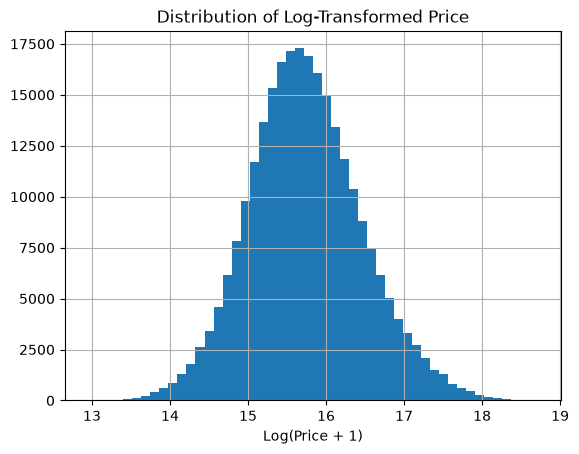

In [3]:
df['log_price_inr'] = np.log1p(df['price_inr'])

print("Original price skewness:", df['price_inr'].skew())
print("Log price skewness:", df['log_price_inr'].skew())

df['log_price_inr'].hist(bins=50)
plt.xlabel('Log(Price + 1)')
plt.title('Distribution of Log-Transformed Price')
plt.show()

## Log-transform the other skewed columns

In [4]:
# Automatically find other skewed columns that genuinely need log-transform 
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
# Detect binary (0/1 only) columns - these should NEVER be log-transformed
binary_cols = [col for col in numeric_cols if set(df[col].dropna().unique()).issubset({0, 1})]

# Exclude: binary flags, price columns already handled, IDs/categories disguised as numbers,
# and coordinates (longitude/latitude are NOT quantities, log-transform is meaningless for them)
exclude_cols = binary_cols + [
    'price_inr', 'log_price_inr', 'price_per_sqft', 'city_tier','bhk', 'bathrooms', 'balconies', 'floor_no', 'total_floors',
    'latitude', 'longitude', 'distance_to_metro_km'  # metro distance handled separately below
]
candidate_cols = [col for col in numeric_cols if col not in exclude_cols]
skewed_cols = [col for col in candidate_cols if abs(df[col].skew()) > 0.75]

print("\nColumns to log-transform:", skewed_cols)

for col in skewed_cols:
    df[f'log_{col}'] = np.log1p(df[col])

for col in skewed_cols:
    print(f"{col}: {df[col].skew():.2f} -> log_{col}: {df[f'log_{col}'].skew():.2f}")


Columns to log-transform: ['super_built_up_area_sqft', 'carpet_area_sqft', 'plot_area_sqft', 'distance_to_city_center_km', 'distance_to_airport_km', 'distance_to_railway_station_km', 'distance_to_school_km', 'distance_to_hospital_km', 'distance_to_mall_km', 'distance_to_it_hub_km', 'property_tax_annual_inr', 'maintenance_charges_monthly_inr']
super_built_up_area_sqft: 1.00 -> log_super_built_up_area_sqft: -0.31
carpet_area_sqft: 1.02 -> log_carpet_area_sqft: -0.31
plot_area_sqft: 1.59 -> log_plot_area_sqft: 0.57
distance_to_city_center_km: 1.90 -> log_distance_to_city_center_km: -0.04
distance_to_airport_km: 1.68 -> log_distance_to_airport_km: -0.04
distance_to_railway_station_km: 1.92 -> log_distance_to_railway_station_km: 0.15
distance_to_school_km: 1.89 -> log_distance_to_school_km: 0.57
distance_to_hospital_km: 1.84 -> log_distance_to_hospital_km: 0.45
distance_to_mall_km: 1.81 -> log_distance_to_mall_km: 0.28
distance_to_it_hub_km: 1.78 -> log_distance_to_it_hub_km: -0.01
propert

### Log for distance_to_metro_km

In [5]:
# Handle distance_to_metro_km separately (because of the -1 placeholder)
df['log_distance_to_metro_km'] = np.where(
    df['distance_to_metro_km'] >= 0,
    np.log1p(df['distance_to_metro_km']), -1
)

print("\nlog_distance_to_metro_km check:")
print(df['log_distance_to_metro_km'].describe())


log_distance_to_metro_km check:
count    260000.000000
mean         -0.162428
std           1.082555
min          -1.000000
25%          -1.000000
50%          -1.000000
75%           0.788457
max           3.044522
Name: log_distance_to_metro_km, dtype: float64


c:\India_house-price-prediction\.venv\Lib\site-packages\pandas\core\arraylike.py:438: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [ ]:
# list every log_ column
print("\nAll log-transformed columns created:", [c for c in df.columns if c.startswith('log_')])


All log-transformed columns created: ['log_price_inr', 'log_super_built_up_area_sqft', 'log_carpet_area_sqft', 'log_plot_area_sqft', 'log_distance_to_city_center_km', 'log_distance_to_airport_km', 'log_distance_to_railway_station_km', 'log_distance_to_school_km', 'log_distance_to_hospital_km', 'log_distance_to_mall_km', 'log_distance_to_it_hub_km', 'log_property_tax_annual_inr', 'log_maintenance_charges_monthly_inr', 'log_distance_to_metro_km']


## Encode categorical columns

### Ordinal encoding

In [11]:
# Drop columns that aren't useful for modeling:
# - property_id: just a unique ID, no predictive meaning
# - locality: too many unique values (thousands), mostly random generated names, no real pattern
# - listing_date: we already proved there's no real time trend
drop_cols = ['property_id', 'locality', 'listing_date']

# Ordinal encoding for flood_risk_zone (it has a genuine order: Low < Medium < High)
flood_order = {'Low': 0, 'Medium': 1, 'High': 2}
df['flood_risk_zone_encoded'] = df['flood_risk_zone'].map(flood_order)

print("Flood risk mapping check:")
print(df[['flood_risk_zone', 'flood_risk_zone_encoded']].drop_duplicates())

Flood risk mapping check:
   flood_risk_zone  flood_risk_zone_encoded
0              Low                        0
2           Medium                        1
10            High                        2


### Check remaining columns

In [12]:
# Identify remaining categorical columns for one-hot encoding
categorical_cols = df.select_dtypes(include=['object', 'str']).columns.tolist()

# Remove columns we're dropping, and remove flood_risk_zone since it's already encoded above
categorical_cols = [col for col in categorical_cols if col not in drop_cols and col != 'flood_risk_zone']

print("\nColumns going through one-hot encoding:", categorical_cols)
for col in categorical_cols:
    print(f"  {col}: {df[col].nunique()} unique values")


Columns going through one-hot encoding: ['city', 'state', 'property_type', 'construction_status', 'possession_status', 'furnishing_status', 'facing', 'society_type', 'water_supply', 'seller_type', 'ownership_type', 'is_negotiable']
  city: 60 unique values
  state: 31 unique values
  property_type: 6 unique values
  construction_status: 2 unique values
  possession_status: 4 unique values
  furnishing_status: 3 unique values
  facing: 8 unique values
  society_type: 3 unique values
  water_supply: 3 unique values
  seller_type: 3 unique values
  ownership_type: 3 unique values
  is_negotiable: 2 unique values


### One-hot encode

In [13]:
# Drop the unneeded columns first
df = df.drop(columns=drop_cols + ['flood_risk_zone'])

# Step 5: One-hot encode everything else
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

print("\nShape before encoding:", df.shape)
print("Shape after encoding:", df_encoded.shape)


Shape before encoding: (260000, 69)
Shape after encoding: (260000, 173)


## Remove leakage/useless columns and build final feature for modeling

In [14]:
# Columns to exclude from training features (leakage risk, IDs, or duplicated by their log version)
log_cols = [col for col in df_encoded.columns if col.startswith('log_')]

raw_versions_of_logged_cols = [
    col.replace('log_', '', 1) for col in log_cols if col.replace('log_', '', 1) in df_encoded.columns
]

# log_price_inr is our target, not a "raw version to exclude" the same way - handle separately
raw_versions_of_logged_cols = [col for col in raw_versions_of_logged_cols if col != 'price_inr']

print("Raw columns to exclude:", raw_versions_of_logged_cols)

Raw columns to exclude: ['super_built_up_area_sqft', 'carpet_area_sqft', 'plot_area_sqft', 'distance_to_city_center_km', 'distance_to_airport_km', 'distance_to_railway_station_km', 'distance_to_school_km', 'distance_to_hospital_km', 'distance_to_mall_km', 'distance_to_it_hub_km', 'property_tax_annual_inr', 'maintenance_charges_monthly_inr', 'distance_to_metro_km']


In [15]:
leakage_cols = ['price_inr', 'price_per_sqft']
exclude_from_features = raw_versions_of_logged_cols + leakage_cols + ['log_price_inr']

X = df_encoded.drop(columns=exclude_from_features)
y = df_encoded['log_price_inr']

print("Feature matrix shape (X):", X.shape)
print("Target shape (y):", y.shape)
print("\nSample feature columns:", X.columns.tolist()[:15])

Feature matrix shape (X): (260000, 157)
Target shape (y): (260000,)

Sample feature columns: ['city_tier', 'latitude', 'longitude', 'bhk', 'bathrooms', 'balconies', 'floor_no', 'total_floors', 'age_of_property_years', 'parking_spots', 'has_lift', 'has_gym', 'has_swimming_pool', 'has_clubhouse', 'has_power_backup']


## Save the dataset

In [17]:
# Save the final feature-engineered dataset
df_encoded.to_csv("../data/processed/india_house_prices_features.csv", index=False)

# Save X and y separately too
joblib.dump(X, "../data/processed/X_features.pkl")
joblib.dump(y, "../data/processed/y_target.pkl")

print("All files saved successfully")

All files saved successfully
